# Sesiunea 17 · CNN: cum văd calculatoarele 🐱

Rulezi o celulă cu **Shift + Enter**. Unde vezi `___`, completezi tu.
Nu poți strica nimic: dacă ceva nu merge, rulează din nou celulele de sus.

## 0. Pregătire

In [1]:
# Rulează celula și atât. Aici sunt uneltele pe care le folosim azi.
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request, io

def arata(*imagini, titluri=None, marime=4):
    n = len(imagini)
    fig, axe = plt.subplots(1, n, figsize=(marime * n, marime))
    axe = [axe] if n == 1 else axe
    for i, (ax, img) in enumerate(zip(axe, imagini)):
        if torch.is_tensor(img):
            img = img.detach().squeeze().numpy()
        img = np.asarray(img)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=img.min(), vmax=np.percentile(img, 99.5))
        else:
            ax.imshow(img)
        ax.axis("off")
        if titluri:
            ax.set_title(titluri[i], fontsize=12)
    plt.tight_layout(); plt.show()

def arata_cu_numere(grila, titlu=""):
    grila = np.asarray(grila.detach() if torch.is_tensor(grila) else grila, dtype=float)
    maxim = 255 if grila.max() > 1 else 1
    fig, ax = plt.subplots(figsize=(0.65 * grila.shape[1] + 1, 0.65 * grila.shape[0] + 1))
    ax.imshow(grila, cmap="gray", vmin=0, vmax=maxim)
    for r in range(grila.shape[0]):
        for c in range(grila.shape[1]):
            v = grila[r, c]
            ax.text(c, r, f"{v:g}", ha="center", va="center", fontsize=10,
                    color="red" if v > maxim / 2 else "yellow")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titlu, fontsize=12)
    plt.show()

def aplica_filtru(imagine, filtru):
    k = torch.tensor(filtru, dtype=torch.float32)
    k = k.reshape(1, 1, *k.shape)
    return F.conv2d(imagine.reshape(1, 1, *imagine.shape), k, padding=k.shape[-1] // 2).squeeze()

def incarca_din_url(url):
    cerere = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return Image.open(io.BytesIO(urllib.request.urlopen(cerere).read())).convert("RGB")

URL_PISICA = "https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg"
pisica_color = incarca_din_url(URL_PISICA)                                      # poza color
pisica = torch.tensor(np.array(pisica_color.convert("L")), dtype=torch.float32) / 255   # alb-negru, 0–1
print("Gata ✅")

Gata ✅


## 1. O imagine = un tabel de numere
0 = negru, 255 = alb.

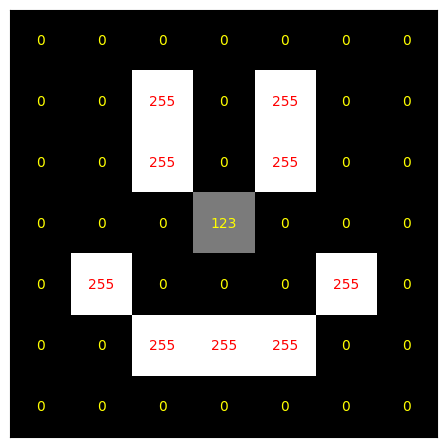

In [3]:
# 🎮 Schimbă câteva 0 în 255 (sau 120 pentru gri) și rulează din nou.
mica = [
    [0,   0,   0, 0,   0,   0, 0],
    [0,   0, 255, 0, 255,   0, 0],
    [0,   0, 255, 0, 255,   0, 0],
    [0,   0,   0, 123,   0,   0, 0],
    [0, 255,   0, 0,   0, 255, 0],
    [0,   0, 255, 255, 255, 0, 0],
    [0,   0,   0, 0,   0,   0, 0],
]
arata_cu_numere(mica)

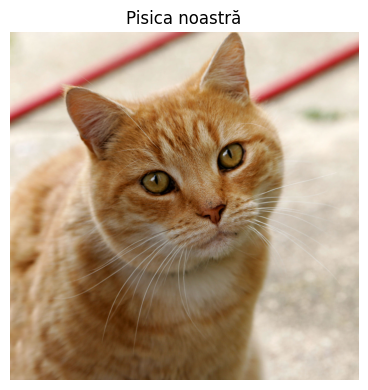

Mărime: 1598 × 1600 = 2556800 de numere


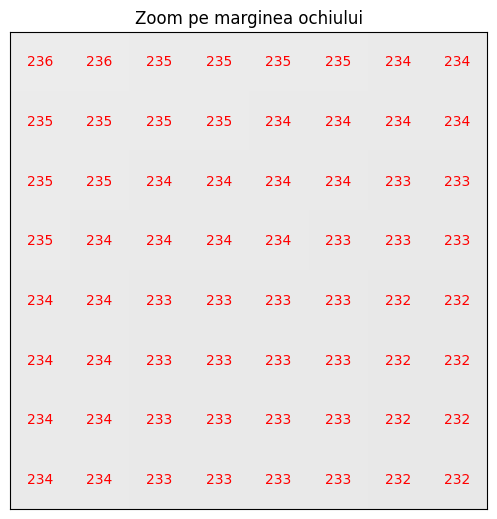

In [4]:
arata(pisica_color, titluri=["Pisica noastră"])
print("Mărime:", pisica.shape[0], "×", pisica.shape[1], "=", pisica.numel(), "de numere")

arata_cu_numere((pisica[84:92, 136:144] * 255).round(), "Zoom pe marginea ochiului")

**Color = 3 tabele:** roșu, verde, albastru.

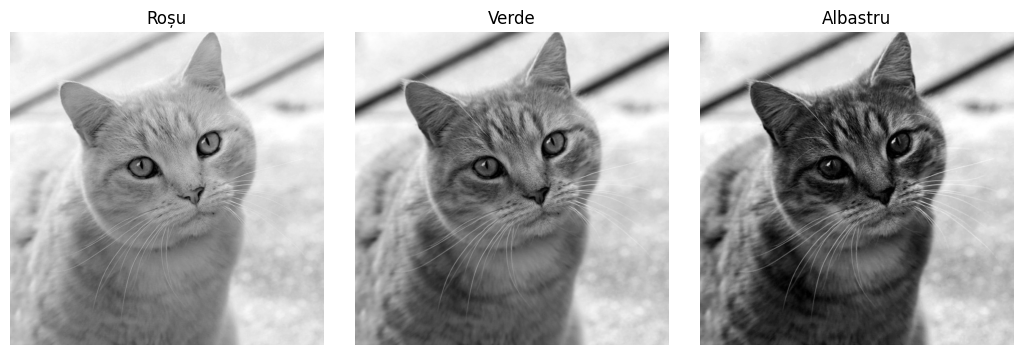

Forma pozei color: (1598, 1600, 3)


In [5]:
rgb = np.array(pisica_color)
arata(rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2], titluri=["Roșu", "Verde", "Albastru"], marime=3.5)
print("Forma pozei color:", rgb.shape)

## 2. Convoluția de mână
Înmulțim pătrățel cu pătrățel și privim rezultatul.

In [ ]:
bucata = torch.tensor([[0, 0, 1],
                       [0, 0, 1],
                       [0, 0, 1]])

filtru = torch.tensor([[-1, 0, 1],
                       [-1, 0, 1],
                       [-1, 0, 1]])

print(bucata * filtru)



## 3. Filtre pe pisică
Același calcul, pe toată poza. Contează doar cele 9 numere din filtru.

In [ ]:
blur = [[1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9]]

margini_verticale = [[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]]

margini_orizontale = [[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]]

accentuare = [[ 0, -1,  0],
              [-1,  5, -1],
              [ 0, -1,  0]]

arata(pisica,
      aplica_filtru(pisica, margini_verticale).abs(),
      aplica_filtru(pisica, margini_orizontale).abs(),
      titluri=["Original", "Margini verticale", "Margini orizontale"], marime=3.5)

In [ ]:
# Alege un filtru: blur, margini_verticale, margini_orizontale sau accentuare
rezultat = aplica_filtru(pisica, ___)
arata(pisica, rezultat.clamp(0, 1), titluri=["Original", "Cu filtru"])

**Exercițiul 3.1:** inventează-ți filtrul. Ce face? Ghicește întâi, apoi rulează.

In [ ]:
# 💡 Idei: un 1 doar într-un colț | toate -1/9 | [[1,0,0],[0,0,0],[0,0,-1]]
filtrul_meu = [[ ___, ___,  ___],
               [ ___, ___,  ___],
               [ ___, ___, ___]]

arata(pisica, aplica_filtru(pisica, filtrul_meu).abs(), titluri=["Original", "Filtrul meu"])

## 4. Conv2d → ReLU → MaxPool
Piesele din care e construit orice CNN.

In [ ]:
conv = nn.Conv2d(in_channels=1, out_channels=___, kernel_size=3, padding=1, bias=False)   # 💡 câte filtre punem?

with torch.no_grad():   # îi dăm noi filtrele, ca să vedem ce fac
    conv.weight[0, 0] = torch.tensor(margini_verticale)
    conv.weight[1, 0] = torch.tensor(margini_orizontale)
    conv.weight[2, 0] = torch.tensor(blur)
    conv.weight[3, 0] = torch.tensor(accentuare)

x = pisica.reshape(1, 1, *pisica.shape)    # [1 poză, 1 canal, înălțime, lățime]
dupa_conv = conv(x)
dupa_relu = F.relu(dupa_conv)              # păstrează doar valorile pozitive
dupa_pool = nn.MaxPool2d(___)(dupa_relu)     # 💡 din fiecare pătrat 2×2 păstrăm maximul

print("Intră:         ", tuple(x.shape))
print("După Conv2d:   ", tuple(dupa_conv.shape))
print("După MaxPool:  ", tuple(dupa_pool.shape))

arata(*[dupa_pool[0, i] for i in range(4)], titluri=["Verticale", "Orizontale", "Blur", "Accentuare"], marime=3.5)

### Exercițiul 4.1 · Urmărește pașii convoluției

Compară aceeași imagine:

1. după Conv2d;
2. după ReLU;
3. după MaxPool.

Ce informație dispare sau se schimbă la fiecare pas?


In [ ]:
arata(
    dupa_conv[0, 0],
    dupa_relu[0, 0],
    dupa_pool[0, 0],
    titluri=["după Conv2d", "după ReLU", "după MaxPool"],
    marime=3.5
)


### Exercițiul 4.2 · Schimbă MaxPool

Schimbă POOL_SIZE în 2 și 4. Privește shape-ul și imaginea rezultată.

De ce devine feature map-ul mai mic?


In [ ]:
POOL_SIZE = 2  # încearcă și 4
pool_nou = nn.MaxPool2d(POOL_SIZE)(dupa_relu)
print("shape nou:", tuple(pool_nou.shape))
arata(pool_nou[0, 0], titluri=[f"MaxPool({POOL_SIZE})"], marime=4)


## Temă / dacă nu apucăm

1. Schimbă margini_verticale și observă ce se întâmplă.
2. Încearcă padding=0 și padding=1. Compară shape-urile.
3. Creează un filtru 3×3 care face blur sau accentuează centrul.
4. Scrie într-o propoziție ce face Conv2d, ce face ReLU și ce face MaxPool.


## 5. ResNet18: un model gata antrenat
Antrenat de alții pe 1,2 milioane de poze, recunoaște 1000 de clase.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=___).eval()       # eval = modul de predicție
clase = weights.meta["categories"]

print("Câte clase știe:", len(clase))
print("Câteva exemple:", clase[281:286])

Poza trebuie pregătită **exact** ca la antrenare. Rețeta vine cu modelul.

In [ ]:
preprocesare = weights.transforms()
print(preprocesare)

x = preprocesare(___)   # 💡 ce poză îi dăm?
print("După preprocesare:", tuple(x.shape))     # [canale, înălțime, lățime]

x = x.unsqueeze(0)
print("Gata pentru model:", tuple(x.shape))     # [batch, canale, înălțime, lățime]

## 6. Ce se întâmplă înăuntru
Poza se micșorează, filtrele se înmulțesc.

In [ ]:
y = x
for nume, strat in model.named_children():
    if nume == "fc":
        y = torch.flatten(y, 1)
    y = strat(y)
    print(f"{nume:10s} {tuple(y.shape)}")

Primele **64 de filtre** din ResNet18. Nimeni nu le-a scris de mână.

In [ ]:
filtre = model.conv1.weight.detach()                         # [64, 3, 7, 7]
filtre = (filtre - filtre.min()) / (filtre.max() - filtre.min())

fig, axe = plt.subplots(8, 8, figsize=(6, 6))
for i, ax in enumerate(axe.flat):
    ax.imshow(filtre[i].permute(1, 2, 0)); ax.axis("off")
plt.show()

harti = F.relu(model.bn1(model.conv1(x)))
arata(*[harti[0, i] for i in range(4)], titluri=[f"Filtrul {i}" for i in range(4)], marime=3)

## 7. Ce vede ResNet18 în poză?

In [ ]:
with torch.no_grad():                          # doar prezicem, nu învățăm
    scoruri = model(x)                         # [1, 1000]: câte un scor pe clasă
    probabilitati = torch.softmax(scoruri, dim=1)

top_prob, top_idx = probabilitati.topk(___)      # 💡 câte răspunsuri vrem?

for p, i in zip(top_prob[0], top_idx[0]):
    print(f"{clase[i]:25s} {p.item():.0%}")

Toți pașii, strânși într-o singură funcție:

In [ ]:
def prezice(poza, cate=5):
    arata(poza)
    x = preprocesare(poza).unsqueeze(0)
    with torch.no_grad():
        probabilitati = torch.softmax(model(x), dim=1)
    top_prob, top_idx = probabilitati.topk(cate)
    for p, i in zip(top_prob[0], top_idx[0]):
        print(f"{clase[i]:25s} {p.item():.0%}")

prezice(pisica_color)

## 8. Poza ta
**Exercițiul 8.1:** link spre o poză (click dreapta pe poză → *Copiază adresa imaginii*).

In [ ]:
url = "___"
prezice(incarca_din_url(url))

**Exercițiul 8.2:** încarcă o poză de pe calculatorul tău. Încearcă și ceva ce nu e în cele 1000 de clase: o persoană, un desen, o frunză.

In [ ]:
from google.colab import files
incarcate = files.upload()
poza_mea = Image.open(list(incarcate.keys())[0]).convert("RGB")
prezice(poza_mea)

## 9. Verifică-te
1. Ce este o imagine pentru calculator?
2. Ce face un filtru? Dă un exemplu.
3. Într-un CNN adevărat, cine alege numerele din filtre?
4. Ce formă are input-ul pentru ResNet18? Ce înseamnă fiecare număr?
5. De ce folosim `weights.transforms()`?
6. Ce face modelul cu o poză care nu e în cele 1000 de clase?